<a href="https://colab.research.google.com/github/SkyWarLimit/PemMes_17/blob/main/JS/11JS11_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1266s 7us/step


In [3]:
from tensorflow.keras import callbacks

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Layer Data Augmentation untuk memperkaya variasi gambar & mencegah overfitting
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

print("Shape train_images:", train_images.shape)
print("Shape test_images :", test_images.shape)

Shape train_images: (50000, 32, 32, 3)
Shape test_images : (10000, 32, 32, 3)


In [4]:
model_cifar = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Blok Konvolusi 1 (32 filters)
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok Konvolusi 2 (64 filters)
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok Konvolusi 3 (128 filters)
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10)
])

model_cifar.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [5]:
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

cb_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_accuracy', factor=0.5, patience=3, min_lr=1e-5, verbose=1
)
cb_early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1
)

In [6]:
history_cifar = model_cifar.fit(
    train_images, train_labels,
    batch_size=64,
    epochs=35,
    validation_data=(test_images, test_labels),
    callbacks=[cb_reduce_lr, cb_early_stop]
)

Epoch 1/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 256s 323ms/step - accuracy: 0.4089 - loss: 1.7264 - val_accuracy: 0.6068 - val_loss: 1.1019 - learning_rate: 0.0010
Epoch 2/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 261s 333ms/step - accuracy: 0.5900 - loss: 1.1588 - val_accuracy: 0.6373 - val_loss: 1.0286 - learning_rate: 0.0010
Epoch 3/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 251s 320ms/step - accuracy: 0.6550 - loss: 0.9847 - val_accuracy: 0.6785 - val_loss: 0.9128 - learning_rate: 0.0010
Epoch 4/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 273s 334ms/step - accuracy: 0.6899 - loss: 0.8924 - val_accuracy: 0.7360 - val_loss: 0.7649 - learning_rate: 0.0010
Epoch 5/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 260s 332ms/step - accuracy: 0.7160 - loss: 0.8278 - val_accuracy: 0.7535 - val_loss: 0.7218 - learning_rate: 0.0010
Epoch 6/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 260s 332ms/step - accuracy: 0.7345 - loss: 0.7726 - val_accuracy: 0.7297 - val_loss: 0.8036 - learning_rate: 0.0010
Epoch 7/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 256s 324ms/step - accura

313/313 - 12s - 38ms/step - accuracy: 0.8736 - loss: 0.3746

Akurasi Testing CIFAR-10: 87.36%


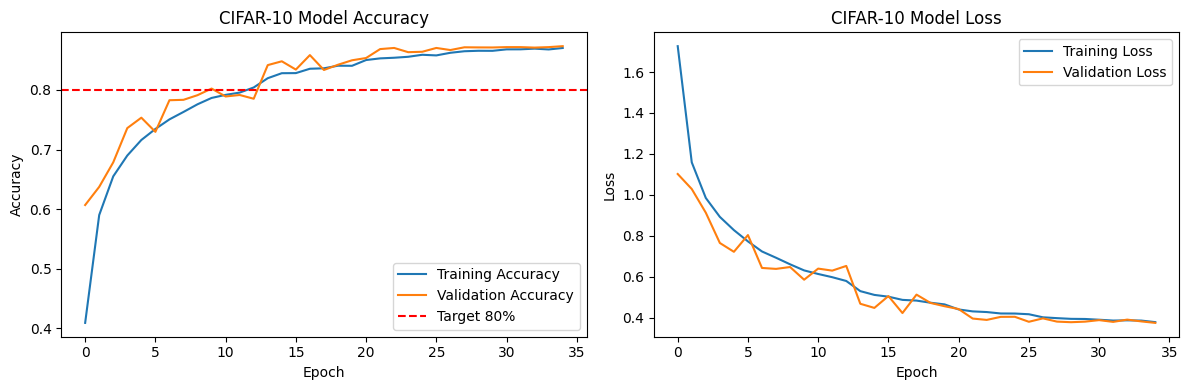

In [7]:
test_loss, test_acc = model_cifar.evaluate(test_images, test_labels, verbose=2)
print(f"\nAkurasi Testing CIFAR-10: {test_acc * 100:.2f}%")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['accuracy'], label='Training Accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='Validation Accuracy')
plt.axhline(y=0.80, color='r', linestyle='--', label='Target 80%')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CIFAR-10 Model Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['loss'], label='Training Loss')
plt.plot(history_cifar.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CIFAR-10 Model Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [8]:
print(test_acc)

0.8736000061035156


In [10]:
import numpy as np

# Load dataset MNIST (60.000 data latih, 10.000 data uji)
(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = datasets.mnist.load_data()

# Reshape ke format 4D (N, 28, 28, 1) untuk grayscale CNN dan normalisasi [0, 1]
x_train_mnist = x_train_mnist.reshape((x_train_mnist.shape[0], 28, 28, 1)).astype("float32") / 255.0
x_test_mnist = x_test_mnist.reshape((x_test_mnist.shape[0], 28, 28, 1)).astype("float32") / 255.0

print("Shape x_train_mnist:", x_train_mnist.shape)
print("Shape x_test_mnist :", x_test_mnist.shape)

Shape x_train_mnist: (60000, 28, 28, 1)
Shape x_test_mnist : (10000, 28, 28, 1)


In [11]:
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10)
])

model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,538 (1.61 MB)

 Trainable params: 422,090 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [12]:
model_mnist.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

history_mnist = model_mnist.fit(
    x_train_mnist, y_train_mnist,
    batch_size=64,
    epochs=10,
    validation_data=(x_test_mnist, y_test_mnist)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 55s 57ms/step - accuracy: 0.9491 - loss: 0.1692 - val_accuracy: 0.9837 - val_loss: 0.0502
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9793 - loss: 0.0674 - val_accuracy: 0.9810 - val_loss: 0.0635
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.9832 - loss: 0.0543 - val_accuracy: 0.9868 - val_loss: 0.0393
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 58ms/step - accuracy: 0.9857 - loss: 0.0456 - val_accuracy: 0.9915 - val_loss: 0.0253
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 79s 55ms/step - accuracy: 0.9877 - loss: 0.0379 - val_accuracy: 0.9881 - val_loss: 0.0356
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.9891 - loss: 0.0349 - val_accuracy: 0.9893 - val_loss: 0.0355
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9897 - loss: 0.0322 - val_accuracy: 0.9918 - val_loss: 0.0235
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 56ms/step - accuracy: 0.9917 - loss: 0.0263 - 

313/313 - 2s - 7ms/step - accuracy: 0.9910 - loss: 0.0304

Akurasi Testing MNIST: 99.10%


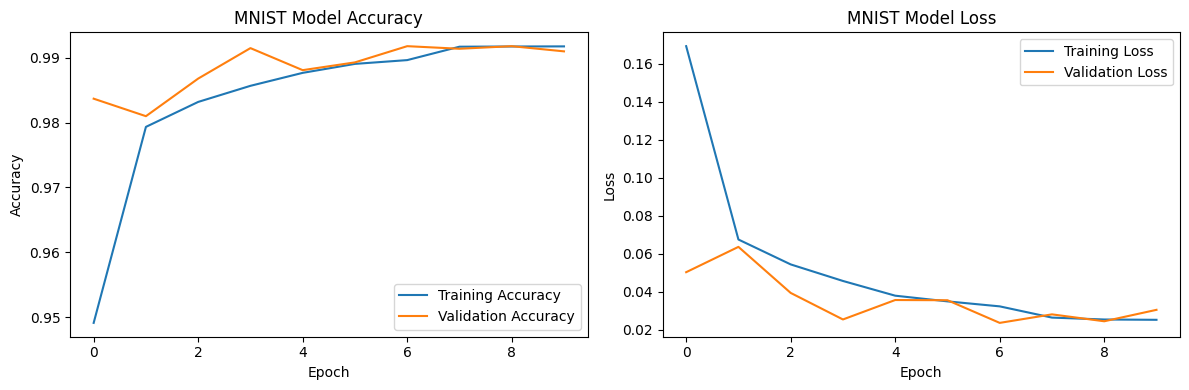

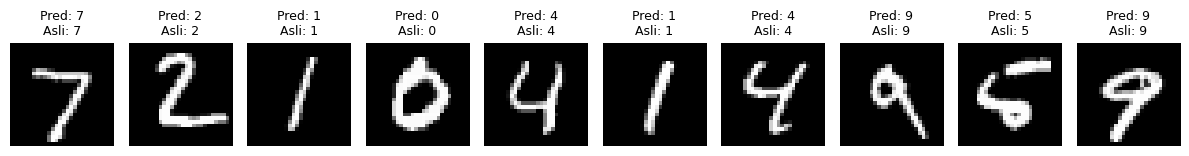

In [13]:
mnist_loss, mnist_acc = model_mnist.evaluate(x_test_mnist, y_test_mnist, verbose=2)
print(f"\nAkurasi Testing MNIST: {mnist_acc * 100:.2f}%")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='Training Accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MNIST Model Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='Training Loss')
plt.plot(history_mnist.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MNIST Model Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Menampilkan 10 contoh prediksi pada data test MNIST
logits = model_mnist.predict(x_test_mnist[:10], verbose=0)
preds = np.argmax(logits, axis=1)

plt.figure(figsize=(12, 2.5))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test_mnist[i].reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {preds[i]}\nAsli: {y_test_mnist[i]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()